In [4]:
import pandas as pd

# Load dataset
df = pd.read_csv("spam.csv", encoding="latin-1")

# Display first 5 rows
df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [5]:
# Keep only required columns
df = df[["v1", "v2"]]

# Rename columns
df.columns = ["label", "message"]

# Remove missing values and duplicates
df = df.dropna()
df = df.drop_duplicates()

# Display dataset information
print(df.head())
print("\nDataset Shape:", df.shape)
print("\nClass Distribution:")
print(df["label"].value_counts())

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset Shape: (5169, 2)

Class Distribution:
label
ham     4516
spam     653
Name: count, dtype: int64


In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer

X = df["message"]
y = df["label"].map({"ham": 0, "spam": 1})

tfidf = TfidfVectorizer(stop_words="english")
X_tfidf = tfidf.fit_transform(X)

print("TF-IDF Matrix Shape:", X_tfidf.shape)

TF-IDF Matrix Shape: (5169, 8404)


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

X_train, X_test, y_train, y_test = train_test_split(
    X_tfidf,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = MultinomialNB()
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


Accuracy: 96.42 %

Classification Report:

              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       903
        Spam       1.00      0.72      0.84       131

    accuracy                           0.96      1034
   macro avg       0.98      0.86      0.91      1034
weighted avg       0.97      0.96      0.96      1034



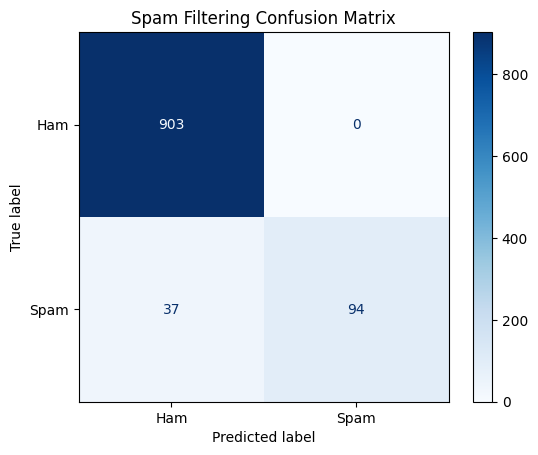

In [8]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=["Ham", "Spam"]))

# Plot confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Ham", "Spam"],
    cmap="Blues"
)

plt.title("Spam Filtering Confusion Matrix")
plt.show()

In [9]:
message = input("Enter a message to check: ")

message_tfidf = tfidf.transform([message])
prediction = model.predict(message_tfidf)[0]

if prediction == 1:
    print("Result: SPAM EMAIL")
else:
    print("Result: HAM (NOT SPAM)")

Enter a message to check:  Congratulations! You have won a free prize. Click now!


Result: SPAM EMAIL
